# Level 3 - Task 2: Support Vector Machine (SVM) for Binary Classification
**Codveda ML Internship**

**Goal:** classify customers as churn / stay with an SVM, compare a **linear** and an **RBF** kernel, and visualise the decision boundary.

**Dataset:** Codveda's churn data (binary target). `churn_train.csv` for training and `churn_test.csv` as the held-out test set.

**Steps:** 1) preprocess and scale, 2) train both kernels, 3) compare metrics, 4) visualise the boundary.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve

DATA_DIR = "../data"  # NB
train = pd.read_csv(f"{DATA_DIR}/churn_train.csv"); test = pd.read_csv(f"{DATA_DIR}/churn_test.csv")
drop_cols = ["State", "Total day charge", "Total eve charge", "Total night charge", "Total intl charge"]
y_train = train["Churn"].astype(int); y_test = test["Churn"].astype(int)
X_train = train.drop(columns=drop_cols + ["Churn"]); X_test = test.drop(columns=drop_cols + ["Churn"])
X_train["Area code"] = X_train["Area code"].astype(str); X_test["Area code"] = X_test["Area code"].astype(str)
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

pre = ColumnTransformer([("num", StandardScaler(), num_cols),
                         ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols)])
Xtr = pre.fit_transform(X_train); Xte = pre.transform(X_test)   # fit on TRAIN only
print("Train:", Xtr.shape, "| Test:", Xte.shape, "| Churn rate (train): %.1f%%" % (y_train.mean() * 100))

Train: (2666, 16) | Test: (667, 16) | Churn rate (train): 14.6%


## Step 1: Preprocess
**What this means:** SVMs measure distances between customers, so features on big scales (like minutes) would swamp small ones (like calls). That is why we **scale** every numeric column, and why the scaler is fitted on the training data only. We drop `State` and the `Total ... charge` columns for the same reasons as in the earlier churn tasks.

## Step 2: Train and compare kernels

Best RBF parameters: {'C': 1, 'gamma': 'scale'}
Baseline accuracy (always 'stay'): 0.858
             Accuracy  Precision  Recall    AUC
Linear          0.858      0.000   0.000  0.781
RBF             0.915      0.896   0.453  0.928
RBF (tuned)     0.915      0.896   0.453  0.928


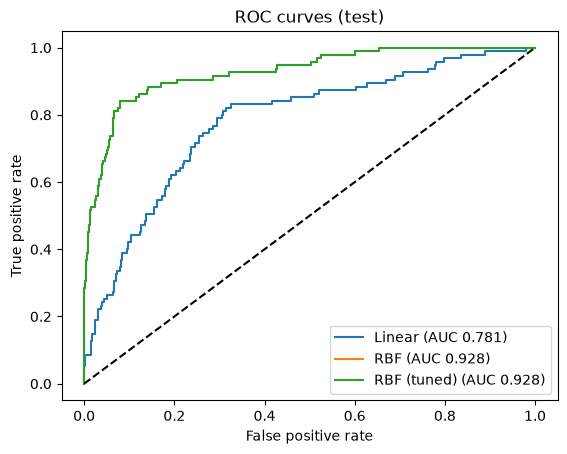

In [2]:
models = {"Linear": SVC(kernel="linear", random_state=42),
          "RBF": SVC(kernel="rbf", random_state=42)}
# A small search to tune the RBF kernel (C = strictness, gamma = how local the curve is)
grid = GridSearchCV(SVC(kernel="rbf", random_state=42), {"C": [0.1, 1, 10], "gamma": ["scale", 0.01, 0.1]},
                    scoring="roc_auc", cv=5, n_jobs=-1).fit(Xtr, y_train)
print("Best RBF parameters:", grid.best_params_)
models["RBF (tuned)"] = grid.best_estimator_

rows, curves = {}, {}
for name, m in models.items():
    m.fit(Xtr, y_train)
    p = m.predict(Xte); score = m.decision_function(Xte)   # distance from the boundary, used for AUC
    rows[name] = {"Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p, zero_division=0),
                  "Recall": recall_score(y_test, p), "AUC": roc_auc_score(y_test, score)}
    curves[name] = roc_curve(y_test, score)
print("Baseline accuracy (always 'stay'): %.3f" % (1 - y_test.mean()))
print(pd.DataFrame(rows).T.round(3))

for name, (fpr, tpr, _) in curves.items():
    plt.plot(fpr, tpr, label="%s (AUC %.3f)" % (name, rows[name]["AUC"]))
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (test)"); plt.legend(); plt.show()

**What this means:**
- A **linear** kernel draws a straight dividing line (flat plane) between the classes; **RBF** can bend the boundary around groups of customers.
- **Accuracy** can look good simply because most customers stay, so compare it with the baseline printed above. **Precision** and **recall** show how well churners themselves are handled, and **AUC** shows how well the model ranks churners above stayers.
- If RBF beats linear, the churn pattern is not a straight line; if they are close, the simpler linear model is enough.
- A model with precision and recall of 0 simply predicted "stay" for every customer, so its accuracy equals the baseline.
- If the tuned row matches the default RBF row, the grid search confirmed that the default settings were already the best of the options tried.

## Step 3: Visualise the decision boundary

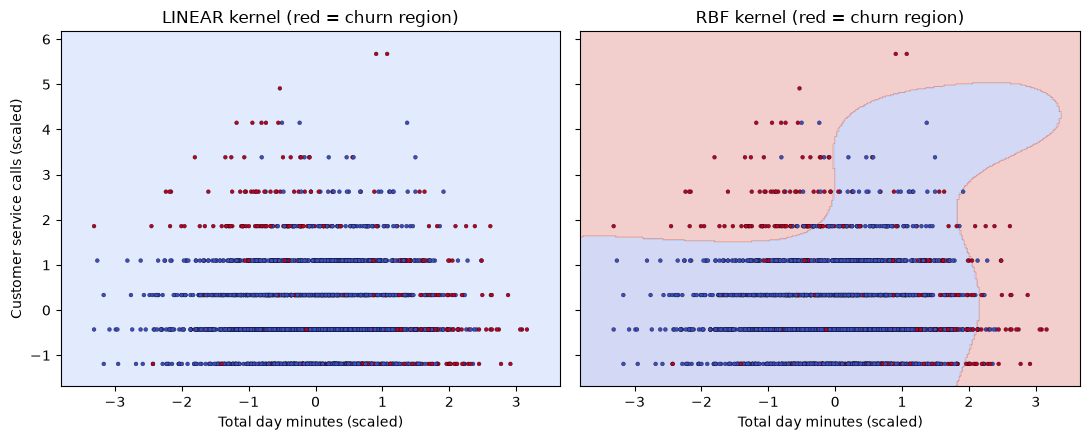

In [3]:
# A boundary can only be drawn in 2D, so we retrain on the two most informative numeric features.
two = ["Total day minutes", "Customer service calls"]
sc = StandardScaler().fit(X_train[two]); A = sc.transform(X_train[two])
xx, yy = np.meshgrid(np.linspace(A[:, 0].min() - .5, A[:, 0].max() + .5, 300),
                     np.linspace(A[:, 1].min() - .5, A[:, 1].max() + .5, 300))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, kernel in zip(axes, ["linear", "rbf"]):
    m2 = SVC(kernel=kernel, random_state=42).fit(A, y_train)
    Z = m2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.25, cmap="coolwarm")
    ax.scatter(A[:, 0], A[:, 1], c=y_train, cmap="coolwarm", s=8, edgecolor="k", linewidth=.2)
    ax.set(xlabel="Total day minutes (scaled)", title="%s kernel (red = churn region)" % kernel.upper())
axes[0].set_ylabel("Customer service calls (scaled)")
plt.tight_layout(); plt.show()

**What this means:** The coloured areas show where the model predicts churn (red) or stay (blue); dots are real customers. This is only an **illustration with 2 features**: the full model above uses all of them, so its results are better than this simplified picture. Notice that the linear kernel finds no useful straight line here and labels the whole area "stay", while the RBF kernel bends its boundary to mark customers with many support calls or very high day minutes as likely churners.

## Conclusion
- SVMs were trained with linear and RBF kernels on scaled churn data, and compared using accuracy, precision, recall and AUC.
- On imbalanced data, accuracy must be read against the "always stay" baseline.
- Scaling is essential for SVMs, and the RBF kernel adds flexibility at the cost of more tuning.
- Next steps: try `class_weight="balanced"` to catch more churners, or compare with the Random Forest from Task 1.